## Exploratory Quality Checks
Plotting distribution across samples of:


*   Relapse vs Relapse Free status
*   ER + vs ER - Status
*   Expression Matrix Distribution
*   Present / Absent / Marginal Distribution
*   P-value of signal detection (signal vs noise detection) distribution
*   Detection rates per ProbeID (row)


### Results Review
| Check | Rationale | Result |
|-|-|-|
|Relapse vs Relapse Free| Bar chart: to see distribution, how many in each category| Unbalanced distribution|
|ER Status| Bar chart: how many ER+ how many ER-| Unbalanced distribution|
|Expression Matrix | Box Plot: visually identify general trend, outliers | Majority of signal is under 60k, with alot of outliers showing higher signal intensity than 60k|
PAM Distribution | We use this information to filter ProbeIDs with weak signals (aka ambiguous if signal or background noise). Used bar chart to get a sense of how many are marked Present Absent or Marginal | Similar amount of Present and Absent, very few marked marginal|
PAM detection rates | Get a more meaningful look at each ProbeID signal strength | U-shaped distribution, with most values either being very strong, or almost no signal at all|
P-value distribution | Heat map: visually see if probes consistently hit the threshold | There seems to be consistency across Probes, but data is too large to make meaningful decisions at this step|
P-value detection rates | Get a more meaningful look at each ProbeID signal strength | U-shaped distribution, with most values either being very strong, or almost no signal at all|

Dataset dimensions: (286, 11134)


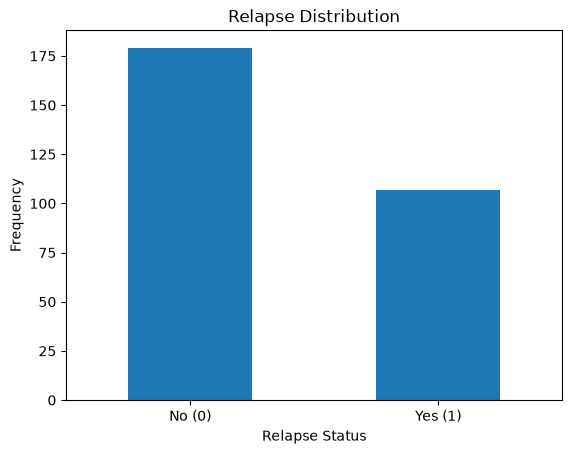

Relapse
0    179
1    107
Name: count, dtype: int64
Relapse Count Relapse
0    179
1    107
Name: count, dtype: int64
Relapse Percentage Relapse
0    62.587413
1    37.412587
Name: count, dtype: float64


In [2]:
'''Distribution of how many patients relapsed versus relapse free'''
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
full_df = pd.read_csv("../data/dashboard_dataset.csv")
relapse_counts = full_df["Relapse"].value_counts()

# Display dataset dimensions
print("Dataset dimensions:", full_df.shape)

# Preview the data
#full_df.head()

'''Plotting and customizing the look of the plot'''
relapse_counts.plot(kind='bar', rot=0)
plt.title('Relapse Distribution')
plt.xlabel('Relapse Status')
plt.ylabel('Frequency')
plt.xticks([0, 1], ['No (0)', 'Yes (1)'])
plt.show()
print (relapse_counts)

'''Showcasing the Raw values of relapse and relapse free, and % of dataset they make up'''
relapse_percentage = ((relapse_counts / len(full_df)) * 100)
print("Relapse Count", relapse_counts)
print("Relapse Percentage", relapse_percentage)

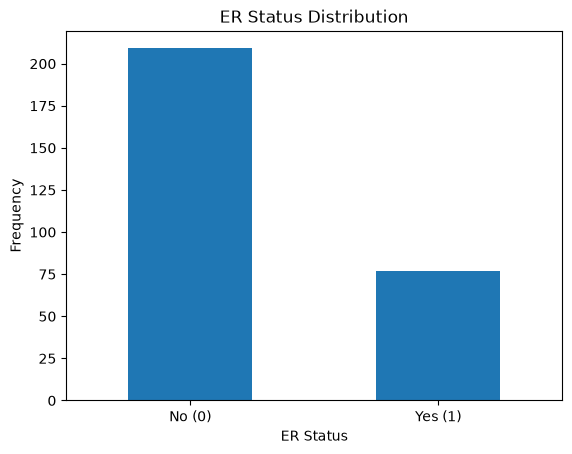

Relapse Count ER_status
ER+    209
ER-     77
Name: count, dtype: int64
Relapse Percentage ER_status
ER+    73.076923
ER-    26.923077
Name: count, dtype: float64


In [3]:
'''Distribution of ER Status'''
ER_counts = full_df['ER_status'].value_counts()

'''Plotting and customizing the look of the plot'''
ER_counts.plot(kind='bar', rot=0)
plt.title('ER Status Distribution')
plt.xlabel('ER Status')
plt.ylabel('Frequency')
plt.xticks([0, 1], ['No (0)', 'Yes (1)'])
plt.show()


'''Showcasing the Raw values of relapse and relapse free, and % of dataset they make up'''
ER_percentage = ((ER_counts / len(full_df)) * 100)
print("Relapse Count", ER_counts)
print("Relapse Percentage", ER_percentage)

#### bivariate analysis

In [4]:
#contingency table, how many ER- samples relapsed versus didn't relapse, and how many ER+ samples relapsed versus didn't relapse.
pd.crosstab(full_df['ER_status'], full_df['Relapse'])

Relapse,0,1
ER_status,,
ER+,129,80
ER-,50,27


In [5]:
#check statistical significance using chi-square
from scipy.stats import chi2_contingency
chi_table = pd.crosstab(full_df['ER_status'], full_df['Relapse'])

chi2, p_value, dof, expected = chi2_contingency(chi_table)

print ('Chi-square statistics:', round(chi2,2))
print ('P-value:', round(p_value,2))

Chi-square statistics: 0.13
P-value: 0.72


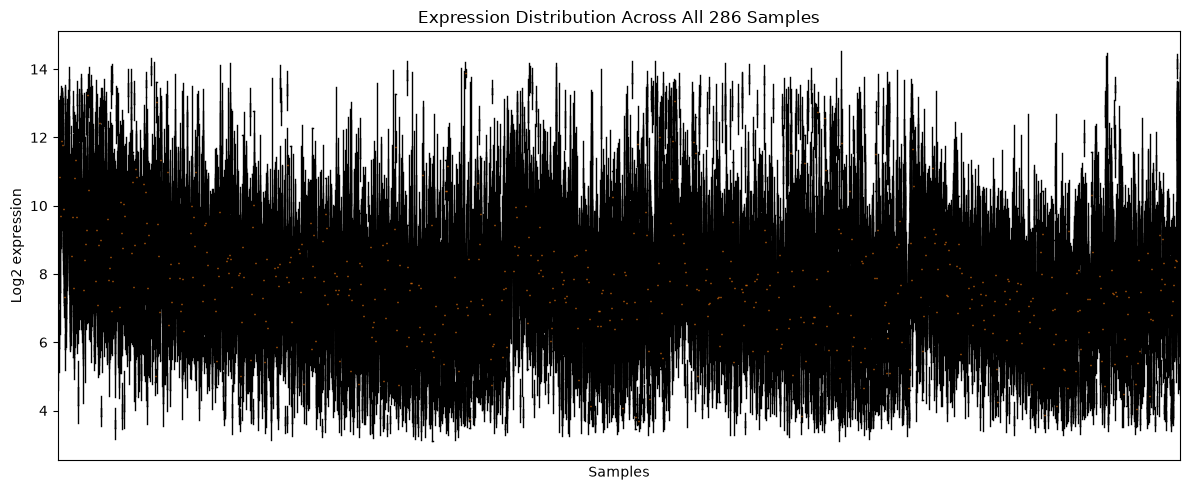

In [6]:
import matplotlib.pyplot as plt

# Remove clinical metadata and retain gene-expression measurements
expression_data = full_df.drop(
    columns=[
        "Sample_Accession",
        "Relapse",
        "ER_status",
        "Follow_up_months"
    ]
)

plt.figure(figsize=(12, 5))

plt.boxplot(
    expression_data,
    showfliers=False
)

plt.xlabel("Samples")
plt.ylabel("Log2 expression")
plt.title("Expression Distribution Across All 286 Samples")
plt.xticks([])

plt.tight_layout()
plt.show()

In [7]:
# Bivariate analysis of relapse groups
from scipy.stats import mannwhitneyu
import pandas as pd


relapse = full_df[full_df['Relapse'] == 1]
no_relapse = full_df[full_df['Relapse'] == 0]


gene_columns = full_df.select_dtypes(
    include='number'
).columns.drop('Relapse')

results = []

for gene in gene_columns:

    group1 = relapse[gene].dropna()
    group0 = no_relapse[gene].dropna()

    stat, p_value = mannwhitneyu(
        group1,
        group0,
        alternative='two-sided'
    )

    results.append({
        'Probe_ID': gene,
        'Relapse_Median': group1.median(),
        'No_Relapse_Median': group0.median(),
        'P_value': p_value
    })

results_df = pd.DataFrame(results)

print(results_df.head())

    Probe_ID  Relapse_Median  No_Relapse_Median   P_value
0  1007_s_at       10.441638          10.399324  0.549578
1    1053_at        6.316510           6.322232  0.929359
2     117_at        6.513652           6.519715  0.418126
3     121_at        8.289112           8.340852  0.397210
4    1294_at        7.941102           7.988678  0.048387


In [8]:
# FDR correction for 11 k probes

from statsmodels.stats.multitest import multipletests


results_df['FDR'] = multipletests(
    results_df['P_value'],
    method='fdr_bh'
)[1]


results_df = results_df.sort_values('FDR')


#print(results_df.head(10))

# Count probes significant after FDR correction
significant_probes = results_df[results_df['FDR'] < 0.05]

print("Total probes tested:", len(results_df))
print("Significant probes:", len(significant_probes))
print("Percentage significant:",
      round(len(significant_probes) / len(results_df) * 100, 2), "%")

Total probes tested: 11131
Significant probes: 266
Percentage significant: 2.39 %


In [9]:
from lifelines import KaplanMeierFitter
print(full_df["Relapse"].value_counts())

print("\nFollow-up summary:")
print(full_df["Follow_up_months"].describe())

Relapse
0    179
1    107
Name: count, dtype: int64

Follow-up summary:
count    286.000000
mean      77.520979
std       42.267958
min        2.000000
25%       37.000000
50%       86.000000
75%      108.000000
max      171.000000
Name: Follow_up_months, dtype: float64


In [10]:
from lifelines import KaplanMeierFitter

# Initialize the Kaplan-Meier estimator
kmf = KaplanMeierFitter()

# Fit the survival model
kmf.fit(
    durations=full_df["Follow_up_months"],
    event_observed=full_df["Relapse"],
    label="Relapse-free survival"
)

# Display survival estimates
print(kmf.survival_function_.head(10))

          Relapse-free survival
timeline                       
0.0                    1.000000
2.0                    0.996503
5.0                    0.993007
6.0                    0.986014
7.0                    0.975524
8.0                    0.968531
9.0                    0.958042
11.0                   0.944056
12.0                   0.940559
13.0                   0.937063


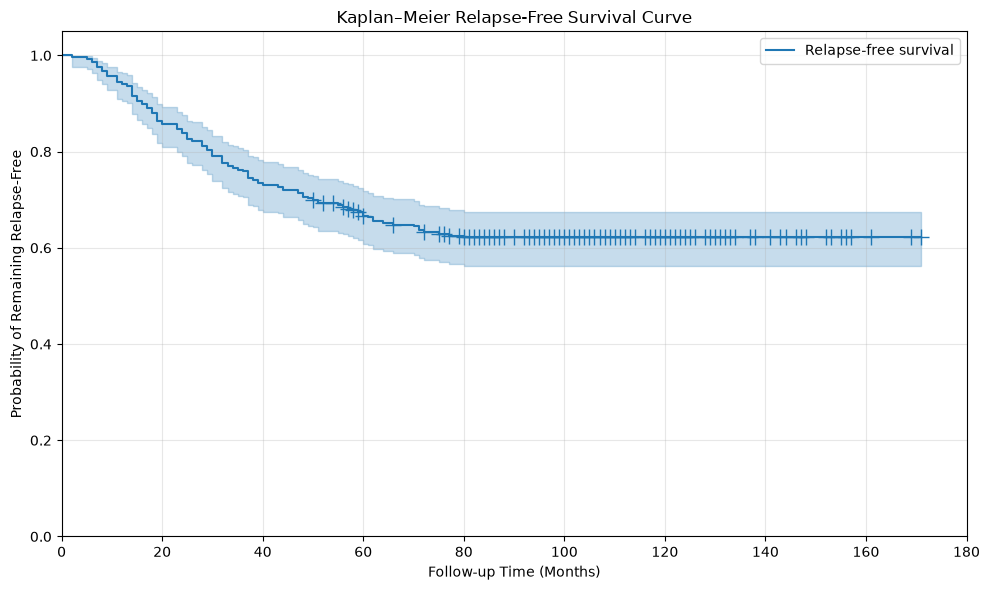

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

kmf.plot_survival_function(
    ci_show=True,
    show_censors=True
)

plt.title("Kaplan–Meier Relapse-Free Survival Curve")
plt.xlabel("Follow-up Time (Months)")
plt.ylabel("Probability of Remaining Relapse-Free")

plt.ylim(0, 1.05)
plt.xlim(0, 180)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
# Extract relapse-free survival estimates at selected time points
time_points = [36, 60, 84, 120]

survival_estimates = kmf.predict(time_points)

print("Relapse-Free Survival Estimates:")
print((survival_estimates * 100).round(2))

Relapse-Free Survival Estimates:
36     75.87
60     66.69
84     62.17
120    62.17
Name: Relapse-free survival, dtype: float64


## Welch's test, FDR Correction, and calculating effect size and inspecting results

In [13]:
# Separate clinical outcome from gene-expression features
X = full_df.drop(
    columns=["Sample_Accession","Relapse", "ER_status", "Follow_up_months"]
)

y = full_df["Relapse"]

print("Expression matrix:", X.shape)
print("\nRelapse groups:")
print(y.value_counts())

#comparing expressions between the two
mean_no_relapse = X[y == 0].mean()
mean_relapse = X[y == 1].mean()

mean_difference = mean_relapse - mean_no_relapse

print(mean_difference.sort_values(ascending=False).head())

print("Expression features:", X.shape[1])
print("Non-numeric columns:", X.select_dtypes(exclude="number").columns.tolist())
print("Missing values:", X.isna().sum().sum())

Expression matrix: (286, 11130)

Relapse groups:
Relapse
0    179
1    107
Name: count, dtype: int64
37892_at       0.700724
204540_at      0.687746
202620_s_at    0.596349
204475_at      0.589552
203878_s_at    0.570910
dtype: float64
Expression features: 11130
Non-numeric columns: []
Missing values: 0


In [14]:
from scipy.stats import ttest_ind

t_stats, p_values = ttest_ind(
    X[y == 1],
    X[y == 0],
    axis=0,
    equal_var=False
)

print("Number of tests:", len(p_values))
print("Smallest p-value:", p_values.min())
print("Raw p-values below 0.05:", (p_values < 0.05).sum())

# We need to implement FDR because there are alot of probes and this many will introduce alot of false positives

from statsmodels.stats.multitest import multipletests

reject, p_adjusted, _, _ = multipletests(
    p_values,
    alpha=0.05,
    method="fdr_bh"
)

print("FDR-significant probes:", reject.sum())
print("Smallest adjusted p-value:", p_adjusted.min())

Number of tests: 11130
Smallest p-value: 4.061262234730934e-09
Raw p-values below 0.05: 2057
FDR-significant probes: 249
Smallest adjusted p-value: 4.5201848672555296e-05


In [15]:
# creating a results dataframe  to make it easier to rank probes

de_results = pd.DataFrame({
    "Probe_ID": X.columns,
    "Mean_No_Relapse": mean_no_relapse.values,
    "Mean_Relapse": mean_relapse.values,
    "Mean_Difference": mean_difference.values,
    "T_Statistic": t_stats,
    "P_Value": p_values,
    "Adjusted_P_Value": p_adjusted,
    "Significant": reject
})

de_results = de_results.sort_values("Adjusted_P_Value")

print(de_results.head(10))
print("\nFDR-significant probes:", de_results["Significant"].sum())

          Probe_ID  Mean_No_Relapse  Mean_Relapse  Mean_Difference  \
1641   202324_s_at         8.492540      8.843365         0.350825   
10613  222077_s_at         6.796308      7.258862         0.462554   
5129   209380_s_at         7.714745      8.136501         0.421756   
5765   210849_s_at         8.485495      8.688922         0.203427   
825    201369_s_at         7.262710      6.767469        -0.495241   
6532     212474_at         7.717969      7.996046         0.278076   
3333     204641_at         6.865599      7.348151         0.482552   
10268    221306_at         6.644204      6.524884        -0.119319   
1885   202620_s_at         7.540189      8.136538         0.596349   
1177     201769_at         8.318151      8.525874         0.207723   

       T_Statistic       P_Value  Adjusted_P_Value  Significant  
1641      6.100365  4.061262e-09          0.000045         True  
10613     5.146727  5.665880e-07          0.003153         True  
5129      4.873072  2.308626e-0

In [16]:
print("FDR-significant probes:", de_results["Significant"].sum())

print("\nSignificant probes by direction:")
print(
    de_results.loc[de_results["Significant"], "Mean_Difference"]
    .gt(0)
    .value_counts()
)

FDR-significant probes: 249

Significant probes by direction:
Mean_Difference
True     159
False     90
Name: count, dtype: int64


## ER status stratification analysis
I want to know, how does ER status relate to Relapse rates. we know that ER status subgrouping alone doesn't seem to be significantly related to relapse, but that doesnt mean it doesn't have an affect on the gene expressions. So in this section, we will compare the most significant gene expressions in ER+, ER- (as they relate to relapse), and then compare the two of them together. <br>
#### Results Summarized

Within the ER+ subgroup, I found 134 probes that are statistically signficant in Relapse, with 90 higher in relapse, and 44 higher in relapse free. <br>
Within the ER- subgroup, there are no signficant probes after FDR correction. This may be due to the small sample size and high dimensionality. <br>
Comparing between the two subgroups becomes tricky because there are no ER- significant probes. However, we can look at the 134 that are signficant in ER+ and see how they behave in ER-. When we analyze this, we find that they have a strong positive correlation. Meaning those 134 seem to behave similarly, higher expression of one in ER+ also seems to show higher expression in ER-. However, this is not confirmation that the patterns are statistically significant, or that these probes are statistically significant in ER-, or that the patterns are identical between the groups. 

In [21]:
# Subset the cohort to ER-positive patients
er_positive_df = full_df[full_df['ER_status'] == 'ER+'].copy()

# Check subgroup counts
print(er_positive_df['Relapse'].value_counts())
print("\nTotal ER-positive patients:", len(er_positive_df))

er_positive_df.head(10)

Relapse
0    129
1     80
Name: count, dtype: int64

Total ER-positive patients: 209


,Sample_Accession,1007_s_at,1053_at,117_at,121_at,1294_at,1316_at,1405_i_at,1487_at,1494_f_at,...,AFFX-r2-Hs18SrRNA-3_s_at,AFFX-r2-Hs18SrRNA-5_at,AFFX-r2-Hs18SrRNA-M_x_at,AFFX-r2-Hs28SrRNA-3_at,AFFX-r2-Hs28SrRNA-5_at,AFFX-r2-P1-cre-3_at,AFFX-r2-P1-cre-5_at,Relapse,Follow_up_months,ER_status
0,GSM36777,10.656269,6.293524,6.785154,8.147451,8.116105,5.543389,6.297705,7.425518,10.121389,...,8.400972,8.037748,7.410176,8.773551,6.837441,13.203729,12.855004,0,79,ER+
1,GSM36778,10.826179,6.105409,6.446397,8.757778,8.046588,5.858173,6.626540,7.458408,6.841101,...,7.721659,6.983152,7.174253,8.256445,6.706327,13.493307,13.060972,1,50,ER+
2,GSM36779,11.126097,6.239484,6.779564,8.530315,8.072878,5.518387,5.466980,7.596806,11.131859,...,9.984656,9.969394,9.311195,10.067197,8.430180,13.838555,13.578604,0,132,ER+
4,GSM36781,10.582677,6.699766,6.682278,8.374228,7.990972,5.629806,9.247610,7.865347,6.683223,...,6.770322,6.333042,5.762516,6.332495,5.918873,13.457076,13.013675,0,147,ER+
5,GSM36782,10.399324,6.315661,6.317047,8.378569,7.886824,5.488902,5.536916,7.454776,6.505783,...,7.117133,6.363386,6.050949,7.392138,5.959482,13.723101,13.371947,0,66,ER+
6,GSM36783,10.989782,6.406297,6.382554,8.531411,7.892833,5.372090,5.429129,7.663597,6.466111,...,7.122519,6.285958,5.465279,6.244494,5.572914,13.449085,13.167953,0,52,ER+
7,GSM36784,10.655691,6.205352,6.466162,8.719074,7.959077,5.815622,6.690181,7.643050,6.898410,...,7.801578,6.748747,6.483454,7.879332,6.146001,13.839671,13.349900,1,57,ER+
8,GSM36785,10.499938,6.394677,6.675949,8.437974,7.663512,5.472751,5.216600,7.499073,8.513593,...,7.250293,6.783158,5.788245,6.698002,5.715680,13.302013,12.964231,0,57,ER+
9,GSM36786,10.586518,6.092160,6.232268,8.159567,7.709658,5.740651,6.983526,7.473912,6.376185,...,6.660164,5.862919,5.502096,6.056732,5.411363,13.065290,12.800083,0,66,ER+
10,GSM36787,11.013969,6.157305,6.658816,8.539290,7.483302,5.918684,6.490312,7.558241,7.623956,...,7.494297,6.806424,6.317081,8.017653,6.089267,13.201154,12.766621,0,72,ER+


In [44]:
# Remove clinical metadata to retain gene-expression measurements
X_er_positive = er_positive_df.drop(columns=[
    'Sample_Accession',
    'Relapse',
    'ER_status',
    'Follow_up_months'
])

X_relapse_pos = X_er_positive[er_positive_df['Relapse'] == 1]
X_no_relapse_pos = X_er_positive[er_positive_df['Relapse'] == 0]

print('Number of samples that showed relapse: ', X_relapse_pos.shape)
print('Number of samples that showed relapse free:', X_no_relapse_pos.shape)

Number of samples that showed relapse:  (80, 11130)
Number of samples that showed relapse free: (129, 11130)


In [45]:
'''The idea here is: we find the mean expression (mean because we'll be using welch's t test), 
of each probe across the samples, for relapse, and non relapse. then we find the difference between 
the means for each probe between relapse and relapse free. The concept is, if there is a big difference, 
it might point to that specific probe being significant'''

# Calculate mean expression for each group
mean_relapse_pos = X_relapse_pos.mean()
mean_no_relapse_pos = X_no_relapse_pos.mean()

# Calculate mean difference
mean_difference_pos = mean_relapse_pos - mean_no_relapse_pos

print (mean_difference_pos)

1007_s_at                   0.020450
1053_at                     0.002755
117_at                      0.010931
121_at                      0.000213
1294_at                    -0.107384
                              ...   
AFFX-r2-Hs18SrRNA-M_x_at   -0.018253
AFFX-r2-Hs28SrRNA-3_at      0.041415
AFFX-r2-Hs28SrRNA-5_at     -0.000092
AFFX-r2-P1-cre-3_at         0.042325
AFFX-r2-P1-cre-5_at         0.053609
Length: 11130, dtype: float64


In [56]:
from scipy.stats import ttest_ind

# Perform Welch's t-test for each gene-expression probe
t_stats, p_values = ttest_ind(
    X_relapse_pos,
    X_no_relapse_pos,
    axis=0,
    equal_var=False
)

print("Number of probes tested:", len(p_values))
print("First 10 p-values:", p_values[:10])
print("First 10 t-statistics:", t_stats[:10])

Number of probes tested: 11130
First 10 p-values: [0.71455243 0.93618524 0.75605437 0.99456507 0.03943313 0.51244813
 0.04107484 0.67956297 0.29723001 0.39987342]
First 10 t-statistics: [ 0.36628655  0.08020012  0.3112227   0.00682183 -2.07692988  0.65666573
 -2.05706662  0.41378937  1.04680786 -0.84421729]


In [57]:
'''we have to apply FDR because this is way too many t tests, and we are introducing alot of area for error'''

from statsmodels.stats.multitest import multipletests

# Adjust p-values for multiple hypothesis testing
reject, adjusted_p_values, _, _ = multipletests(
    p_values,
    method='fdr_bh'
)

print("Number of FDR-significant probes:", reject.sum())
print("First 10 adjusted p-values:", adjusted_p_values[:10])

Number of FDR-significant probes: 134
First 10 adjusted p-values: [0.88380056 0.97884512 0.90610786 0.99913435 0.27655374 0.78316925
 0.28272295 0.86739507 0.63372262 0.71369326]


In [ ]:
'''bringing our results together so we can rank the probes and eventually create our volcano plot'''

de_results_er_positive = pd.DataFrame({
    "Probe_ID": X_er_positive.columns,
    "Mean_No_Relapse": mean_no_relapse.values,
    "Mean_Relapse": mean_relapse.values,
    "Mean_Difference": mean_difference.values,
    "T_Statistic": t_stats,
    "P_Value": p_values,
    "Adjusted_P_Value": adjusted_p_values,
    "Significant": reject
})

# Sort by adjusted p-value
de_results_er_positive = de_results_er_positive.sort_values(
    by="Adjusted_P_Value"
)

de_results_er_positive.head()

,Probe_ID,Mean_No_Relapse,Mean_Relapse,Mean_Difference,T_Statistic,P_Value,Adjusted_P_Value,Significant
1641,202324_s_at,8.535256,8.860429,0.325172,4.867563,0.000002,0.006647,True
10613,222077_s_at,6.674449,7.204328,0.529879,4.990817,0.000002,0.006647,True
4743,208905_at,9.915223,10.209365,0.294142,5.058438,0.000001,0.006647,True
3333,204641_at,6.730398,7.289013,0.558615,4.918720,0.000002,0.006647,True
5765,210849_s_at,8.507400,8.730763,0.223363,4.757954,0.000004,0.009009,True


In [35]:
# Filter for statistically significant probes
significant_er_positive = de_results_er_positive[
    de_results_er_positive["Significant"] == True
]

# Count direction of expression differences
higher_in_relapse = (
    significant_er_positive["Mean_Difference"] > 0
).sum()

higher_in_no_relapse = (
    significant_er_positive["Mean_Difference"] < 0
).sum()

print("Total significant probes:", len(significant_er_positive))
print("Higher in relapse:", higher_in_relapse)
print("Higher in no relapse:", higher_in_no_relapse)

Total significant probes: 134
Higher in relapse: 90
Higher in no relapse: 44


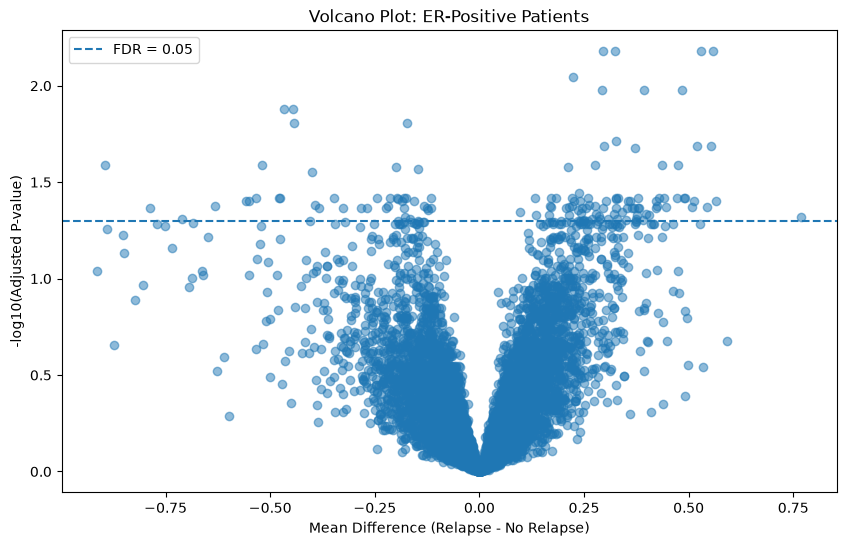

In [36]:
import matplotlib.pyplot as plt
import numpy as np

# Calculate -log10 of adjusted p-values
de_results_er_positive["Neg_Log10_P"] = -np.log10(
    de_results_er_positive["Adjusted_P_Value"]
)

# Create volcano plot
plt.figure(figsize=(10, 6))

plt.scatter(
    de_results_er_positive["Mean_Difference"],
    de_results_er_positive["Neg_Log10_P"],
    alpha=0.5
)

# Add significance threshold
plt.axhline(
    -np.log10(0.05),
    linestyle="--",
    label="FDR = 0.05"
)

plt.xlabel("Mean Difference (Relapse - No Relapse)")
plt.ylabel("-log10(Adjusted P-value)")
plt.title("Volcano Plot: ER-Positive Patients")
plt.legend()
plt.show()

### ER- stratification

We put the ER- samples into one dataframe and split them by relapse status. then we found the mean of each probe id for both relapse and relapse free. then we find the differences between each mean (mean_probe1_relapse - mean_probe1_nonrelapse), and test to see if these differences seem signficant using welch's t test and FDR correction. Wierdly, no probes passed the FDR correction. Maybe this is because it is a very small sample size (77 in total), and it is very high dimensionality (11k probes)

In [37]:
# Subset the cohort to ER-negative patients
er_negative_df = full_df[full_df['ER_status'] == 'ER-'].copy()

# Check subgroup counts
print(er_negative_df['Relapse'].value_counts())
print("\nTotal ER-negative patients:", len(er_negative_df))

er_negative_df.head(10)

Relapse
0    50
1    27
Name: count, dtype: int64

Total ER-negative patients: 77


,Sample_Accession,1007_s_at,1053_at,117_at,121_at,1294_at,1316_at,1405_i_at,1487_at,1494_f_at,...,AFFX-r2-Hs18SrRNA-3_s_at,AFFX-r2-Hs18SrRNA-5_at,AFFX-r2-Hs18SrRNA-M_x_at,AFFX-r2-Hs28SrRNA-3_at,AFFX-r2-Hs28SrRNA-5_at,AFFX-r2-P1-cre-3_at,AFFX-r2-P1-cre-5_at,Relapse,Follow_up_months,ER_status
3,GSM36780,10.477855,6.628975,6.673216,8.499970,7.719168,5.735773,7.427322,7.726948,6.511897,...,8.643687,7.821658,7.371878,8.287202,6.714380,13.537538,13.089998,0,84,ER-
11,GSM36788,10.306474,6.666544,6.457088,8.519088,8.363216,5.727634,9.145360,7.688474,6.502227,...,8.091901,6.897114,6.702281,7.816578,6.233041,13.088149,12.861493,0,79,ER-
14,GSM36791,10.490000,6.256589,6.408425,8.760865,7.855805,5.733277,5.895982,7.470175,6.934842,...,7.229137,6.484571,5.955044,7.452371,5.832521,13.764135,13.488859,0,79,ER-
16,GSM36793,10.741495,6.105680,6.354932,8.753997,7.889930,5.523064,7.056721,7.867163,6.602208,...,5.780041,5.636898,4.455242,5.128783,5.595730,12.652896,12.359263,0,101,ER-
18,GSM36795,10.461018,6.408723,7.077587,8.505520,8.070499,5.756921,6.296901,7.349408,6.949749,...,7.844187,6.853399,6.567899,7.340974,6.053921,13.515501,13.140827,0,88,ER-
20,GSM36797,10.286120,6.483997,6.409913,8.807743,7.855280,5.624725,7.097323,7.500536,6.697531,...,7.238890,6.540807,5.622861,6.459653,6.014600,12.749978,12.330687,1,9,ER-
21,GSM36798,10.133956,6.269394,6.754328,8.715463,8.108538,5.650924,8.654065,7.465600,6.904747,...,9.140486,7.682008,6.882094,7.963821,7.078169,13.298949,13.045451,0,106,ER-
23,GSM36800,10.893900,6.444995,6.828128,8.618176,7.977736,5.628919,5.694151,7.508737,6.663180,...,7.461955,6.772342,6.266688,7.093180,5.942692,13.362674,12.967962,1,37,ER-
31,GSM36808,10.585476,6.483720,6.775733,8.620798,8.002823,5.609093,6.999303,7.767072,6.904601,...,7.856346,6.834897,6.547964,7.409787,5.888824,13.761628,13.433824,0,58,ER-
32,GSM36809,9.867931,6.345880,7.016605,8.454568,7.963754,5.699393,8.110613,7.455023,6.740636,...,8.411942,7.531049,7.281453,8.342037,6.681678,13.680885,13.369428,0,56,ER-


In [39]:
# Remove clinical metadata to retain gene-expression measurements
X_er_negative = er_negative_df.drop(columns=[
    'Sample_Accession',
    'Relapse',
    'ER_status',
    'Follow_up_months'
])

X_relapse_neg = X_er_negative[er_negative_df['Relapse'] == 1]
X_no_relapse_neg = X_er_negative[er_negative_df['Relapse'] == 0]

print('Number of samples that showed relapse: ', X_relapse.shape)
print('Number of samples that showed relapse free:', X_no_relapse.shape)

Number of samples that showed relapse:  (27, 11130)
Number of samples that showed relapse free: (50, 11130)


In [40]:
'''differences in means of probes across samples'''

# Calculate mean expression for each group
mean_relapse_neg = X_relapse_neg.mean()
mean_no_relapse_neg = X_no_relapse_neg.mean()

# Calculate mean difference
mean_difference_neg = mean_relapse_neg - mean_no_relapse_neg

print (mean_difference_neg)

1007_s_at                  -0.073304
1053_at                     0.020216
117_at                     -0.053649
121_at                     -0.069780
1294_at                    -0.084519
                              ...   
AFFX-r2-Hs18SrRNA-M_x_at    0.054210
AFFX-r2-Hs28SrRNA-3_at      0.114356
AFFX-r2-Hs28SrRNA-5_at      0.145095
AFFX-r2-P1-cre-3_at        -0.096148
AFFX-r2-P1-cre-5_at        -0.094470
Length: 11130, dtype: float64


In [60]:
from scipy.stats import ttest_ind

# Perform Welch's t-test for each gene-expression probe
t_stats_neg, p_values_neg = ttest_ind(
    X_relapse_neg,
    X_no_relapse_neg,
    axis=0,
    equal_var=False
)

print("Number of probes tested:", len(p_values_neg))
print("First 10 p-values:", p_values_neg[:10])
print("First 10 t-statistics:", t_stats_neg[:10])

Number of probes tested: 11130
First 10 p-values: [0.58133956 0.78011569 0.68185652 0.28333747 0.33411903 0.78362077
 0.1666027  0.91859407 0.0909219  0.46146048]
First 10 t-statistics: [-0.5561686   0.28069065 -0.41327334 -1.08642721 -0.97354079 -0.27587335
 -1.39886914  0.10272835 -1.71290324  0.7416539 ]


In [64]:
'''we have to apply FDR because this is way too many t tests, and we are introducing alot of area for error'''

from statsmodels.stats.multitest import multipletests

# Adjust ER-negative p-values for multiple testing
reject_neg, adjusted_p_values_neg, _, _ = multipletests(
    p_values_neg,
    method='fdr_bh'
)

print("Number of FDR-significant probes:", reject_neg.sum())
print("First 10 adjusted p-values:", adjusted_p_values_neg[:10])
print("Smallest raw p-value:", p_values_neg.min())
print("Smallest adjusted p-value:", adjusted_p_values_neg.min())
print("Significant probes:", reject_neg.sum())

Number of FDR-significant probes: 0
First 10 adjusted p-values: [0.95090689 0.97317728 0.96439608 0.87905601 0.89451141 0.97470934
 0.84941981 0.99253055 0.84321545 0.93286204]
Smallest raw p-value: 0.00016267960376223586
Smallest adjusted p-value: 0.7675681821311464
Significant probes: 0


In [65]:
'''Getting 0 fdr significant probes, which is weird so I am just verifying'''
print("ER-negative relapse patients:", X_relapse_neg.shape[0])
print("ER-negative no-relapse patients:", X_no_relapse_neg.shape[0])
print("Relapse probes:", X_relapse_neg.shape[1])
print("No-relapse probes:", X_no_relapse_neg.shape[1])
print(X_relapse_neg.shape)
print(X_no_relapse_neg.shape)

ER-negative relapse patients: 27
ER-negative no-relapse patients: 50
Relapse probes: 11130
No-relapse probes: 11130
(27, 11130)
(50, 11130)


In [66]:
'''bringing our results together so we can rank the probes and eventually create our volcano plot'''

de_results_er_negative = pd.DataFrame({
    "Probe_ID": X_er_negative.columns,
    "Mean_No_Relapse": mean_no_relapse_neg.values,
    "Mean_Relapse": mean_relapse_neg.values,
    "Mean_Difference": mean_difference_neg.values,
    "T_Statistic": t_stats_neg,
    "P_Value": p_values_neg,
    "Adjusted_P_Value": adjusted_p_values_neg,
    "Significant": reject_neg
})

# Sort by adjusted p-value
de_results_er_negative = de_results_er_negative.sort_values(
    by="Adjusted_P_Value"
)

de_results_er_negative.head()

,Probe_ID,Mean_No_Relapse,Mean_Relapse,Mean_Difference,T_Statistic,P_Value,Adjusted_P_Value,Significant
1476,202130_at,8.669273,9.068058,0.398784,3.697954,0.000487,0.767568,False
8750,218047_at,8.420916,8.811938,0.391021,3.466315,0.000973,0.767568,False
1641,202324_s_at,8.382330,8.792805,0.410475,3.617880,0.000651,0.767568,False
8602,217880_at,6.496665,6.785712,0.289047,3.588813,0.000669,0.767568,False
1762,202464_s_at,8.109233,8.586005,0.476772,3.611202,0.000563,0.767568,False


In [67]:
# Filter for statistically significant probes
significant_er_negative = de_results_er_negative[
    de_results_er_negative["Significant"] == True
]

# Count direction of expression differences
higher_in_relapse_neg = (
    significant_er_negative["Mean_Difference"] > 0
).sum()

higher_in_no_relapse_neg = (
    significant_er_negative["Mean_Difference"] < 0
).sum()

print("Total significant probes:", len(significant_er_negative))
print("Higher in relapse:", higher_in_relapse_neg)
print("Higher in no relapse:", higher_in_no_relapse_neg)

Total significant probes: 0
Higher in relapse: 0
Higher in no relapse: 0


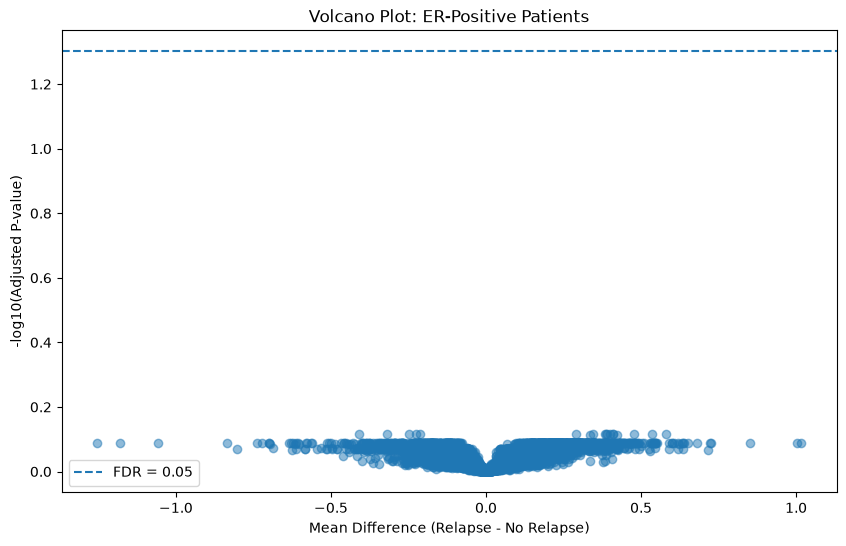

In [68]:
import matplotlib.pyplot as plt
import numpy as np

# Calculate -log10 of adjusted p-values
de_results_er_negative["Neg_Log10_P"] = -np.log10(
    de_results_er_negative["Adjusted_P_Value"]
)

# Create volcano plot
plt.figure(figsize=(10, 6))

plt.scatter(
    de_results_er_negative["Mean_Difference"],
    de_results_er_negative["Neg_Log10_P"],
    alpha=0.5
)

# Add significance threshold
plt.axhline(
    -np.log10(0.05),
    linestyle="--",
    label="FDR = 0.05"
)

plt.xlabel("Mean Difference (Relapse - No Relapse)")
plt.ylabel("-log10(Adjusted P-value)")
plt.title("Volcano Plot: ER-Positive Patients")
plt.legend()
plt.show()

### Comparing ER+ and ER- 
Since the ER- subgroup produced 0 signficant probes, we will do this analysis mostly for effect size. 

In [70]:
# Merge ER-positive and ER-negative results
comparison_df = pd.merge(
    de_results_er_positive,
    de_results_er_negative,
    on="Probe_ID",
    suffixes=("_ER_Positive", "_ER_Negative")
)

print("Number of probes compared:", len(comparison_df))
comparison_df.head()

Number of probes compared: 11130


,Probe_ID,Mean_No_Relapse_ER_Positive,Mean_Relapse_ER_Positive,Mean_Difference_ER_Positive,T_Statistic_ER_Positive,P_Value_ER_Positive,Adjusted_P_Value_ER_Positive,Significant_ER_Positive,Neg_Log10_P_ER_Positive,Mean_No_Relapse_ER_Negative,Mean_Relapse_ER_Negative,Mean_Difference_ER_Negative,T_Statistic_ER_Negative,P_Value_ER_Negative,Adjusted_P_Value_ER_Negative,Significant_ER_Negative,Neg_Log10_P_ER_Negative
0,202324_s_at,8.535256,8.860429,0.325172,4.867563,0.000002,0.006647,True,2.177370,8.382330,8.792805,0.410475,3.617880,0.000651,0.767568,False,0.114883
1,222077_s_at,6.674449,7.204328,0.529879,4.990817,0.000002,0.006647,True,2.177370,7.110704,7.420444,0.309740,1.992236,0.050663,0.813794,False,0.089486
2,208905_at,9.915223,10.209365,0.294142,5.058438,0.000001,0.006647,True,2.177370,10.243379,10.287034,0.043655,0.392828,0.695937,0.967100,False,0.014529
3,204641_at,6.730398,7.289013,0.558615,4.918720,0.000002,0.006647,True,2.177370,7.214417,7.523374,0.308957,1.433057,0.157528,0.849420,False,0.070878
4,210849_s_at,8.507400,8.730763,0.223363,4.757954,0.000004,0.009009,True,2.045335,8.428981,8.564948,0.135967,1.546636,0.127048,0.849420,False,0.070878


In [ ]:
'''This is different from FDR, here I want to know are the expression patterns associated with relapse directionally consistent between ER+ and ER-?
this includes all probes, not just significant ones'''
# Compare expression direction between ER subgroups
same_direction = (
    (comparison_df["Mean_Difference_ER_Positive"] > 0) &
    (comparison_df["Mean_Difference_ER_Negative"] > 0)
) | (
    (comparison_df["Mean_Difference_ER_Positive"] < 0) &
    (comparison_df["Mean_Difference_ER_Negative"] < 0)
)

opposite_direction = (
    (comparison_df["Mean_Difference_ER_Positive"] > 0) &
    (comparison_df["Mean_Difference_ER_Negative"] < 0)
) | (
    (comparison_df["Mean_Difference_ER_Positive"] < 0) &
    (comparison_df["Mean_Difference_ER_Negative"] > 0)
)

print("Same direction (AKA consistent b/t ER+ and ER-):", same_direction.sum())
print("Opposite direction(AKA direction reversed b/t ER+ and ER-):", opposite_direction.sum())

Same direction (AKA consistent b/t ER+ and ER-): 7028
Opposite direction(AKA direction reversed b/t ER+ and ER-): 4102


In [ ]:
'''calculating correlation between mean expressions in the two subgroups
hopefully will tell us whether probes with larger relapse associated differences in ER+ are also larger in ER-'''
correlation = comparison_df[
    "Mean_Difference_ER_Positive"
].corr(
    comparison_df["Mean_Difference_ER_Negative"]
)

print("Correlation between ER subgroups:", correlation)

'''We see there is a marginal positive correlation, but it is not strong, there is still considerable variation between two subgroups'''

Correlation between ER subgroups: 0.39169020183841713


### Comparing probes significant in ER+ and see how they behave in ER-
we can't check for overlap of probes between the two groups, because ER- has no signficiant probes. BUT we can take the 134 signficant probes in ER+ and look at their mean differences in ER- and see what they're up to over there.<br>
When we look at the correlation, we see that probes that are higher in ER+ tend to be higher in ER- negative as well, there seems to be a pretty strong positive correlation. <BR>
BUT! we can't conclude that these expression patterns are statistically signficant in ER-, or that the patterns are identical between the two subgroups.

In [74]:
# Extract probes significant in the ER-positive subgroup
er_positive_significant = comparison_df[
    comparison_df["Significant_ER_Positive"] == True
].copy()

print("Number of probes:", len(er_positive_significant))

Number of probes: 134


In [76]:
# Count expression directions in ER-positive
higher_relapse_er_pos = (
    er_positive_significant["Mean_Difference_ER_Positive"] > 0
).sum()

higher_no_relapse_er_pos = (
    er_positive_significant["Mean_Difference_ER_Positive"] < 0
).sum()

# Count expression directions in ER-negative
higher_relapse_er_neg = (
    er_positive_significant["Mean_Difference_ER_Negative"] > 0
).sum()

higher_no_relapse_er_neg = (
    er_positive_significant["Mean_Difference_ER_Negative"] < 0
).sum()

print("ER-positive:")
print("Higher in relapse:", higher_relapse_er_pos)
print("Higher in no relapse:", higher_no_relapse_er_pos)

print("\nER-negative:")
print("Higher in relapse:", higher_relapse_er_neg)
print("Higher in no relapse:", higher_no_relapse_er_neg)

ER-positive:
Higher in relapse: 90
Higher in no relapse: 44

ER-negative:
Higher in relapse: 87
Higher in no relapse: 47


In [77]:
correlation_134 = er_positive_significant[
    "Mean_Difference_ER_Positive"
].corr(
    er_positive_significant["Mean_Difference_ER_Negative"]
)

print("Correlation among 134 ER-positive significant probes:", correlation_134)

Correlation among 134 ER-positive significant probes: 0.7629533649636835


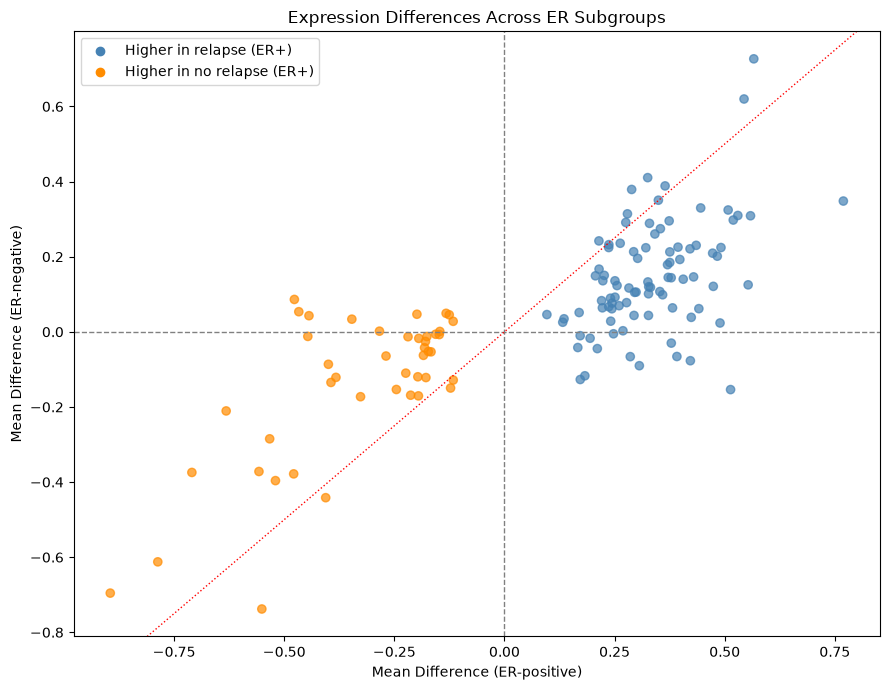

In [ ]:
import matplotlib.pyplot as plt

# Assign colours based on ER-positive direction
colours = [
    "steelblue" if value > 0 else "darkorange"
    for value in er_positive_significant["Mean_Difference_ER_Positive"]
]

plt.figure(figsize=(9, 7))

plt.scatter(
    er_positive_significant["Mean_Difference_ER_Positive"],
    er_positive_significant["Mean_Difference_ER_Negative"],
    c=colours,
    alpha=0.7
)

# Reference lines
plt.axhline(0, color="grey", linestyle="--", linewidth=1)
plt.axvline(0, color="grey", linestyle="--", linewidth=1)
plt.axline((0, 0), slope=1, color="red", linestyle=":", linewidth=1)

plt.xlabel("Mean Difference (ER-positive)")
plt.ylabel("Mean Difference (ER-negative)")
plt.title("ER+ Significant Probes: Expression Differences Compared Across ER Subgroups")

# Legend
plt.scatter([], [], color="steelblue", label="Higher in relapse (ER+)")
plt.scatter([], [], color="darkorange", label="Higher in no relapse (ER+)")
plt.legend()

plt.tight_layout()
plt.show()